# GAN on MNIST — CPU-Safe Classroom Version

## Why this corrected version exists

The earlier notebook failed with:

`InvalidArgumentError: No DNN in stream executor`

That error comes from the **GPU/CUDA/cuDNN runtime**, not from the GAN mathematics.

This version is deliberately designed to be very reliable for classroom use:

- It **forces TensorFlow to use the CPU**.
- It uses a **fully connected (Dense) GAN** rather than `Conv2D` / `Conv2DTranspose`.
- It therefore avoids the convolutional DNN operations that caused the runtime error.
- It still teaches the complete GAN idea: **Generator vs Discriminator, adversarial loss, training, and generated MNIST digits**.
- It includes an optional **digit recognizer** at the end.

> **Before running:** In Google Colab choose **Runtime → Restart session**, then run this notebook from the first cell using **Runtime → Run all**.

## 1. Force CPU mode and import libraries

**Important:** Run this cell first, before any other TensorFlow code.

For this teaching experiment, CPU mode is intentional and avoids the broken GPU/cuDNN path.

In [1]:
# IMPORTANT: this must appear before importing TensorFlow.
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Extra safety: hide GPUs if TensorFlow has not initialized them yet.
try:
    tf.config.set_visible_devices([], "GPU")
except RuntimeError:
    pass

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Visible GPUs:", tf.config.get_visible_devices("GPU"))
print("Running in CPU-safe mode.")

2026-08-24 08:24:52.087452: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-08-24 08:24:52.117646: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8473] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-08-24 08:24:52.125304: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1471] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-08-24 08:24:52.147182: I tensorflow/core/platform/cpu_feature_guard.cc:211] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.17.0
Visible GPUs: []
Running in CPU-safe mode.


2026-08-24 08:24:55.829533: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


## 2. Load MNIST

MNIST contains 60,000 training images and 10,000 test images.  
Each image is **28 × 28 = 784 pixels**.

For the GAN:
- flatten each image to 784 values;
- normalize pixels from **[0, 255]** to **[-1, 1]**;
- use `tanh` in the Generator output layer.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Test images:", x_test.shape)

# Keep original copies for display and classification.
x_train_original = x_train.copy()
x_test_original = x_test.copy()

# Normalize to [-1, 1] and flatten from (28,28) to 784.
x_train_gan = x_train.astype("float32")
x_train_gan = (x_train_gan - 127.5) / 127.5
x_train_gan = x_train_gan.reshape(-1, 784)

print("GAN training shape:", x_train_gan.shape)
print("Pixel range:", x_train_gan.min(), "to", x_train_gan.max())

Training images: (60000, 28, 28)
Test images: (10000, 28, 28)
GAN training shape: (60000, 784)
Pixel range: -1.0 to 1.0


## 3. View real MNIST digits

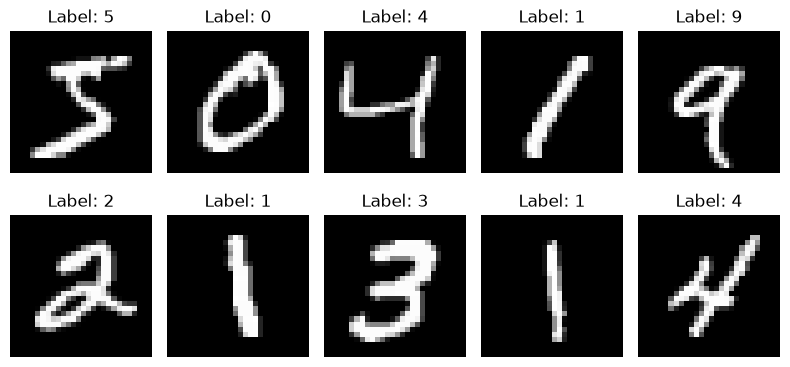

In [3]:
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_original[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Build the input pipeline

In [4]:
BATCH_SIZE = 256
BUFFER_SIZE = x_train_gan.shape[0]

train_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train_gan)
    .shuffle(BUFFER_SIZE, seed=SEED)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Batches per epoch:", BUFFER_SIZE // BATCH_SIZE)

Batches per epoch: 234


# Part A — Build the GAN

## 5. Generator

The Generator receives random noise and creates a 784-pixel image.

Architecture:

`100 random values → 256 → 512 → 1024 → 784 pixels`

The output uses **tanh**, so pixels lie in **[-1, 1]**.

In [5]:
NOISE_DIM = 100

def build_generator():
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(NOISE_DIM,)),
            tf.keras.layers.Dense(256),
            tf.keras.layers.LeakyReLU(0.2),
            tf.keras.layers.BatchNormalization(),

            tf.keras.layers.Dense(512),
            tf.keras.layers.LeakyReLU(0.2),
            tf.keras.layers.BatchNormalization(),

            tf.keras.layers.Dense(1024),
            tf.keras.layers.LeakyReLU(0.2),
            tf.keras.layers.BatchNormalization(),

            tf.keras.layers.Dense(784, activation="tanh"),
        ],
        name="generator",
    )

generator = build_generator()
generator.summary()

Model: "generator"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 256)               25856     
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 256)               0         
                                                                 
 batch_normalization (Batch  (None, 256)               1024      
 Normalization)                                                  
                                                                 
 dense_1 (Dense)             (None, 512)               131584    
                                                                 
 leaky_re_lu_1 (LeakyReLU)   (None, 512)               0         
                                                                 
 batch_normalization_1 (Bat  (None, 512)               2048      
 chNormalization)                                        

## 6. Check the untrained Generator

Before training, the output should look like noise.

Generator output shape: (1, 784)


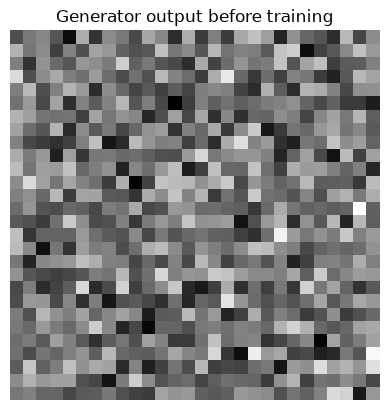

In [6]:
noise = tf.random.normal([1, NOISE_DIM])
generated_vector = generator(noise, training=False)
generated_image = tf.reshape(generated_vector[0], (28, 28))

print("Generator output shape:", generated_vector.shape)

plt.imshow(generated_image, cmap="gray")
plt.title("Generator output before training")
plt.axis("off")
plt.show()

## 7. Discriminator

The Discriminator receives 784 pixel values and predicts whether the image looks **real or fake**.

Architecture:

`784 pixels → 512 → 256 → 1 real/fake score`

In [7]:
def build_discriminator():
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(784,)),
            tf.keras.layers.Dense(512),
            tf.keras.layers.LeakyReLU(0.2),
            tf.keras.layers.Dropout(0.3),

            tf.keras.layers.Dense(256),
            tf.keras.layers.LeakyReLU(0.2),
            tf.keras.layers.Dropout(0.3),

            tf.keras.layers.Dense(1),
        ],
        name="discriminator",
    )

discriminator = build_discriminator()
discriminator.summary()

Model: "discriminator"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_4 (Dense)             (None, 512)               401920    
                                                                 
 leaky_re_lu_3 (LeakyReLU)   (None, 512)               0         
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_5 (Dense)             (None, 256)               131328    
                                                                 
 leaky_re_lu_4 (LeakyReLU)   (None, 256)               0         
                                                                 
 dropout_1 (Dropout)         (None, 256)               0         
                                                                 
 dense_6 (Dense)             (None, 1)               

## 8. Check the untrained Discriminator

In [8]:
decision = discriminator(generated_vector, training=False)
print("Discriminator score:", float(decision[0, 0]))

Discriminator score: -0.03524567559361458


## 9. GAN loss functions

We use **Binary Cross-Entropy**.

### Discriminator
- Real image → target 1
- Fake image → target 0

### Generator
The Generator wants fake images to be classified as real, so its target is 1.

In [9]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output), real_output
    )
    fake_loss = cross_entropy(
        tf.zeros_like(fake_output), fake_output
    )
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output), fake_output
    )

## 10. Optimizers

In [10]:
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002, beta_1=0.5
)

## 11. One GAN training step

For each mini-batch:

1. Generate fake digits from random noise.
2. Give real and fake images to the Discriminator.
3. Calculate Generator and Discriminator losses.
4. Calculate gradients.
5. Update both models.

In [11]:
@tf.function
def train_step(real_images):
    current_batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal(
        [current_batch_size, NOISE_DIM]
    )

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(
            real_output, fake_output
        )

    generator_gradients = gen_tape.gradient(
        gen_loss, generator.trainable_variables
    )
    discriminator_gradients = disc_tape.gradient(
        disc_loss, discriminator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            generator_gradients,
            generator.trainable_variables,
        )
    )

    discriminator_optimizer.apply_gradients(
        zip(
            discriminator_gradients,
            discriminator.trainable_variables,
        )
    )

    return gen_loss, disc_loss

## 12. Function to display generated digits

In [12]:
NUM_EXAMPLES = 16
fixed_seed = tf.random.normal(
    [NUM_EXAMPLES, NOISE_DIM], seed=SEED
)

def show_generated_images(model, epoch=None):
    predictions = model(fixed_seed, training=False)
    predictions = tf.reshape(
        predictions, (-1, 28, 28)
    )

    plt.figure(figsize=(6, 6))

    for i in range(NUM_EXAMPLES):
        plt.subplot(4, 4, i + 1)

        # Convert [-1,1] to [0,1] for display.
        image = (predictions[i] + 1.0) / 2.0
        plt.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1,
        )
        plt.axis("off")

    if epoch is None:
        plt.suptitle("Generated digits")
    else:
        plt.suptitle(
            f"Generated digits after epoch {epoch}"
        )

    plt.tight_layout()
    plt.show()

## 13. Train the GAN

For a classroom demonstration, start with **10 epochs**.

If you want better-looking generated digits, change `EPOCHS` to **20 or 30**.

2026-08-24 08:25:31.810306: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 01/50 | Generator loss: 3.1312 | Discriminator loss: 0.1965 | Time: 13.4s


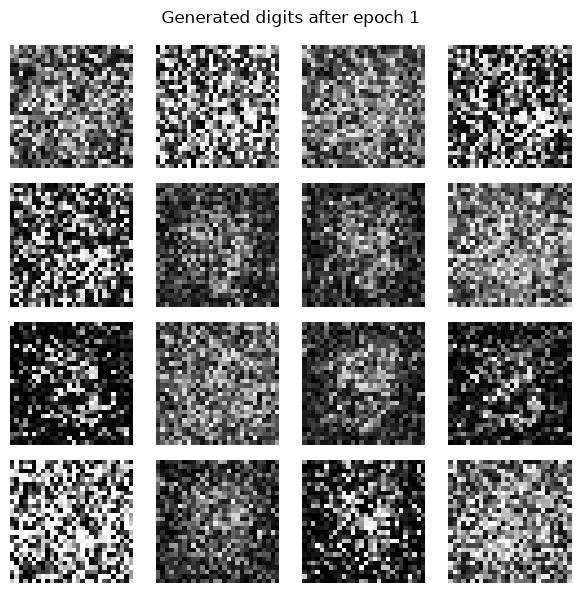

2026-08-24 08:25:40.697690: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 02/50 | Generator loss: 0.9254 | Discriminator loss: 1.1383 | Time: 8.6s


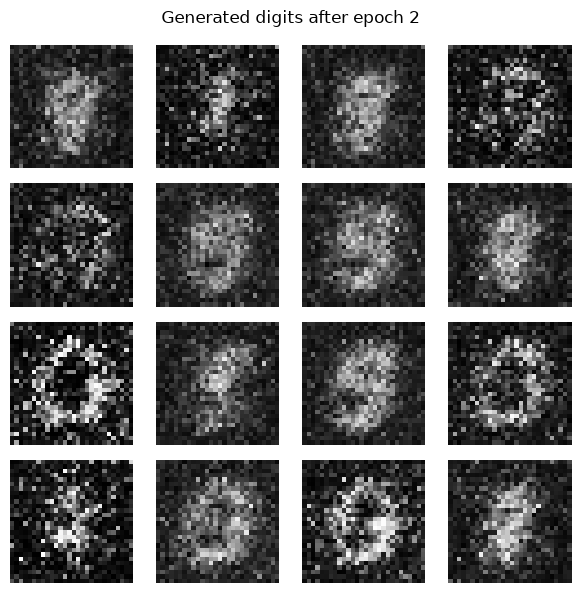

Epoch 03/50 | Generator loss: 0.7104 | Discriminator loss: 1.2622 | Time: 9.1s


2026-08-24 08:25:58.858284: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 04/50 | Generator loss: 0.7671 | Discriminator loss: 1.2347 | Time: 8.8s


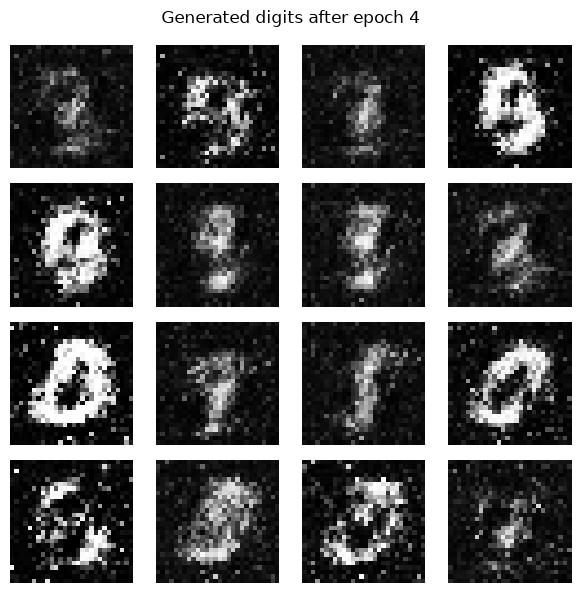

Epoch 05/50 | Generator loss: 0.8481 | Discriminator loss: 1.1805 | Time: 9.0s
Epoch 06/50 | Generator loss: 0.9030 | Discriminator loss: 1.1559 | Time: 9.3s


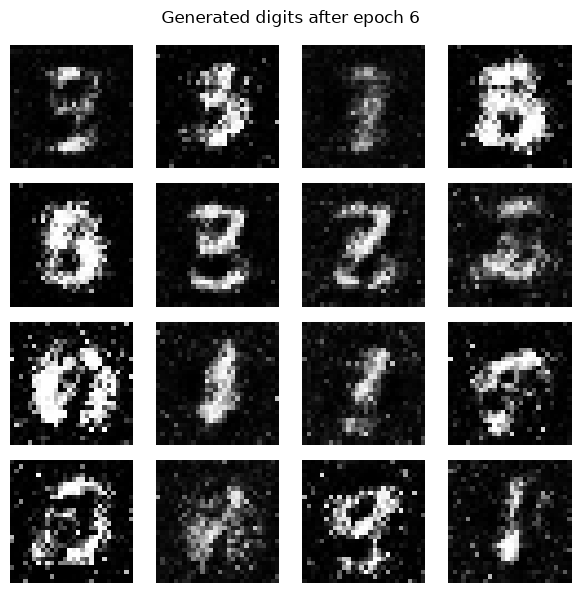

Epoch 07/50 | Generator loss: 0.9555 | Discriminator loss: 1.1353 | Time: 9.2s


2026-08-24 08:26:36.768683: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 08/50 | Generator loss: 0.9818 | Discriminator loss: 1.1194 | Time: 9.5s


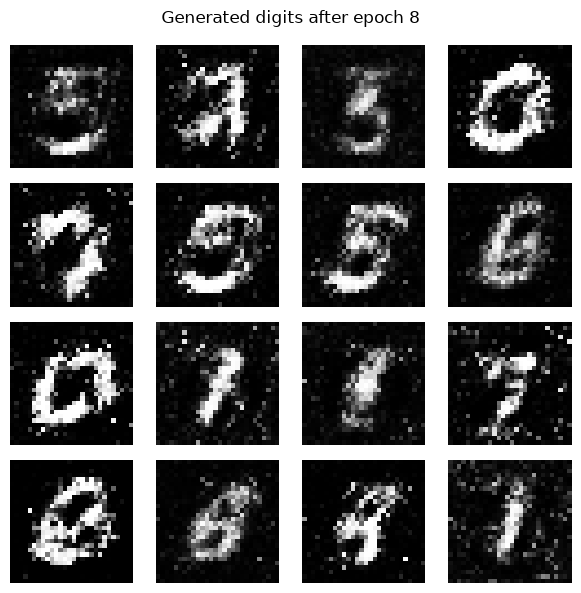

Epoch 09/50 | Generator loss: 0.9864 | Discriminator loss: 1.1260 | Time: 9.4s
Epoch 10/50 | Generator loss: 1.0080 | Discriminator loss: 1.1135 | Time: 10.2s


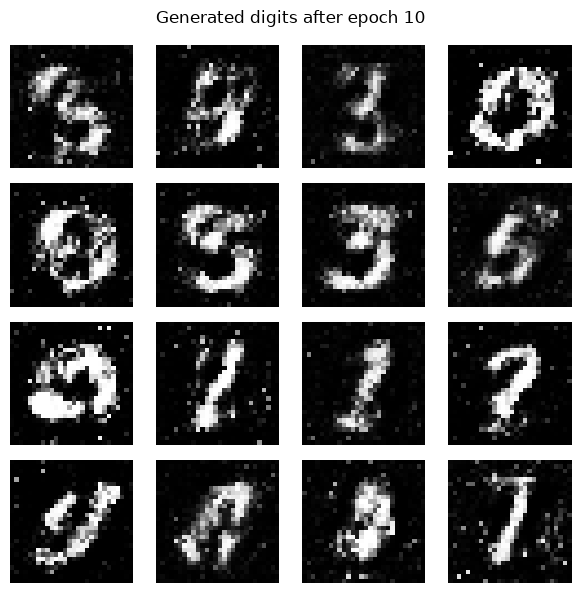

Epoch 11/50 | Generator loss: 0.9711 | Discriminator loss: 1.1530 | Time: 10.4s
Epoch 12/50 | Generator loss: 0.9978 | Discriminator loss: 1.1317 | Time: 9.0s


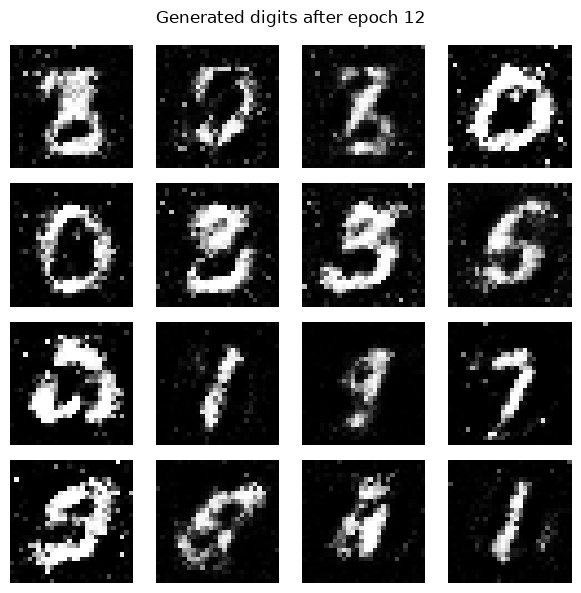

Epoch 13/50 | Generator loss: 0.9817 | Discriminator loss: 1.1600 | Time: 10.0s
Epoch 14/50 | Generator loss: 0.9597 | Discriminator loss: 1.1700 | Time: 10.7s


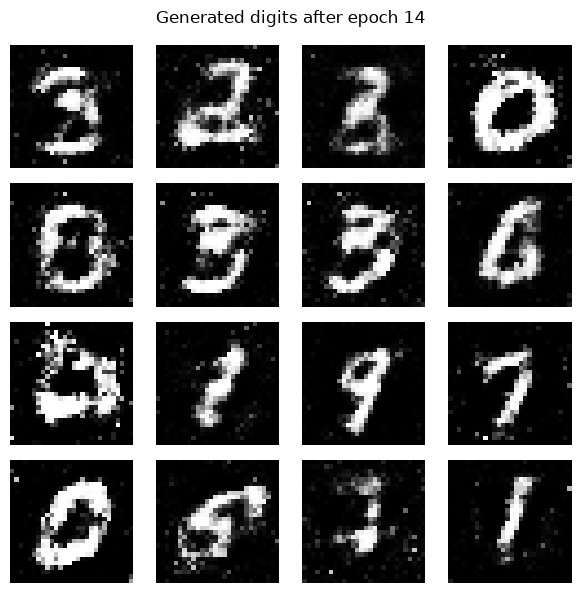

Epoch 15/50 | Generator loss: 0.9456 | Discriminator loss: 1.1882 | Time: 10.4s


2026-08-24 08:27:59.337343: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 16/50 | Generator loss: 0.9262 | Discriminator loss: 1.2107 | Time: 11.3s


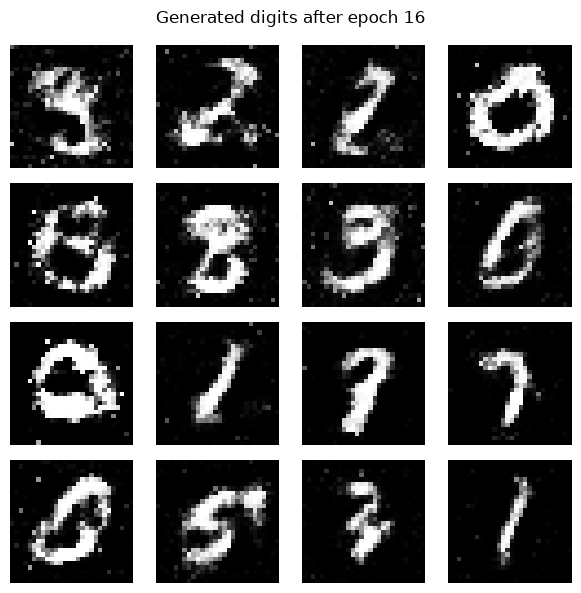

Epoch 17/50 | Generator loss: 0.9113 | Discriminator loss: 1.2192 | Time: 9.7s
Epoch 18/50 | Generator loss: 0.8964 | Discriminator loss: 1.2378 | Time: 9.5s


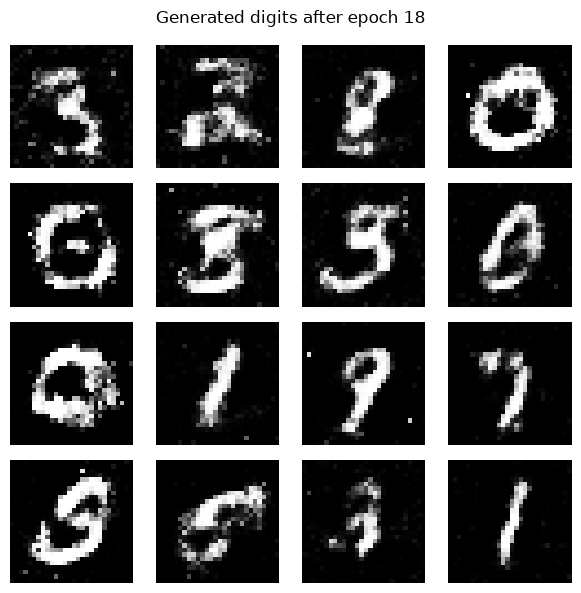

Epoch 19/50 | Generator loss: 0.8763 | Discriminator loss: 1.2580 | Time: 9.3s
Epoch 20/50 | Generator loss: 0.8691 | Discriminator loss: 1.2593 | Time: 9.4s


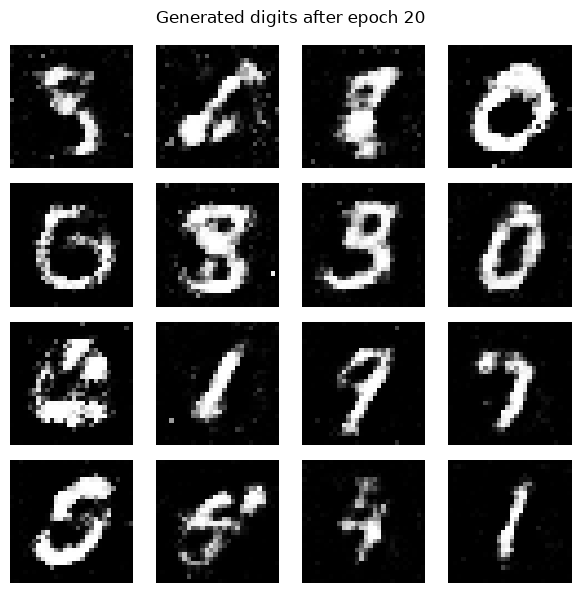

Epoch 21/50 | Generator loss: 0.8607 | Discriminator loss: 1.2692 | Time: 9.7s
Epoch 22/50 | Generator loss: 0.8555 | Discriminator loss: 1.2761 | Time: 9.5s


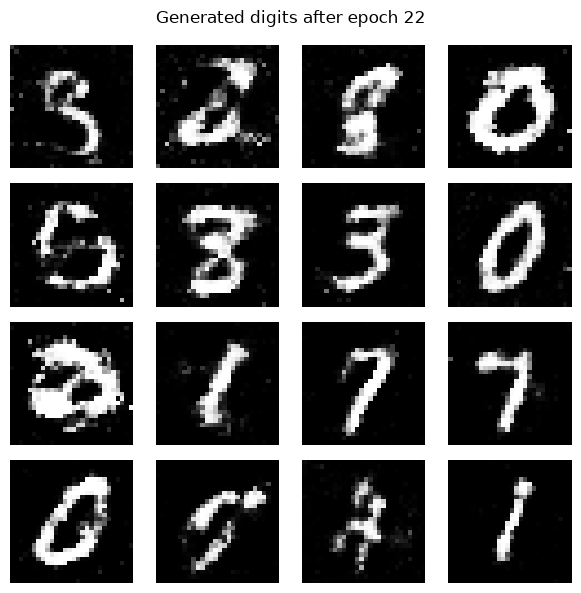

Epoch 23/50 | Generator loss: 0.8427 | Discriminator loss: 1.2885 | Time: 9.0s
Epoch 24/50 | Generator loss: 0.8366 | Discriminator loss: 1.2901 | Time: 9.5s


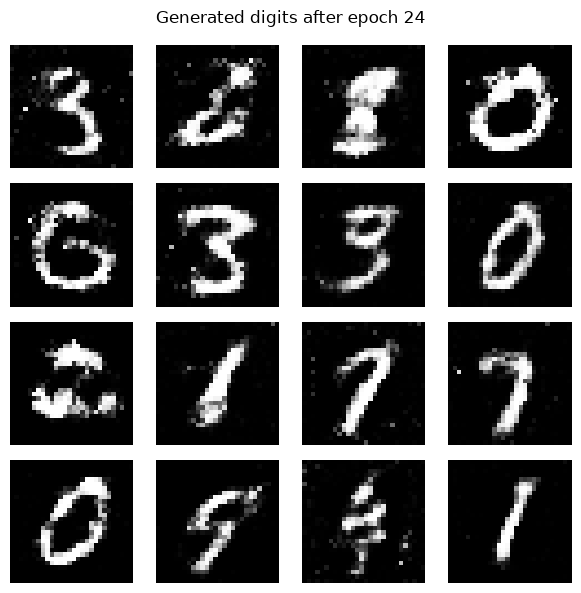

Epoch 25/50 | Generator loss: 0.8295 | Discriminator loss: 1.2965 | Time: 9.6s
Epoch 26/50 | Generator loss: 0.8232 | Discriminator loss: 1.3040 | Time: 9.9s


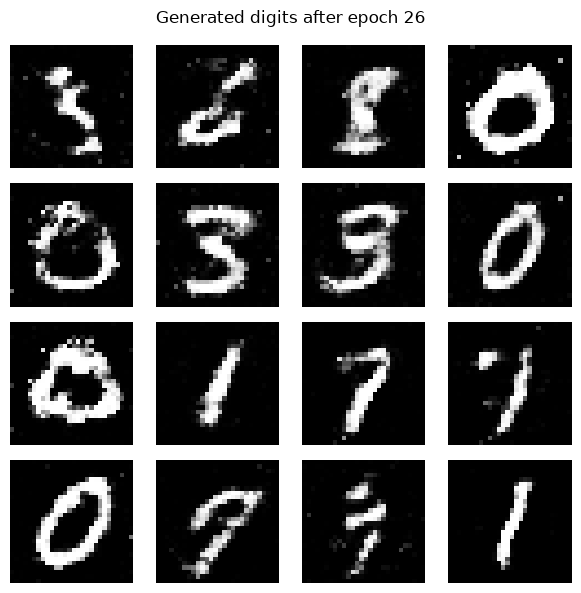

Epoch 27/50 | Generator loss: 0.8207 | Discriminator loss: 1.3030 | Time: 10.4s
Epoch 28/50 | Generator loss: 0.8140 | Discriminator loss: 1.3141 | Time: 10.0s


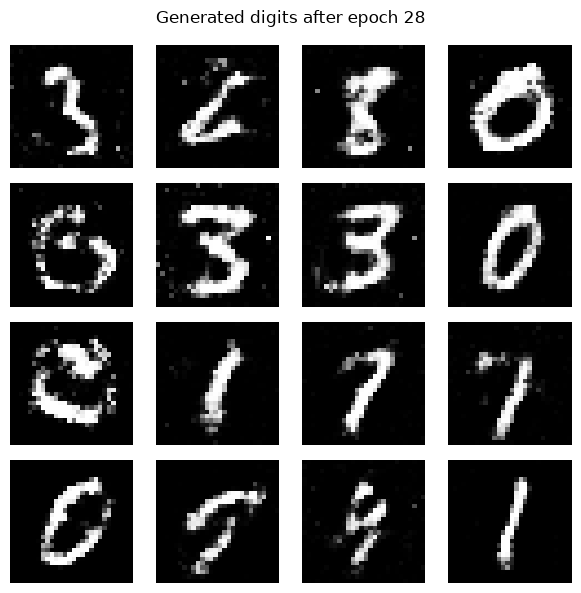

Epoch 29/50 | Generator loss: 0.8124 | Discriminator loss: 1.3115 | Time: 9.5s
Epoch 30/50 | Generator loss: 0.8068 | Discriminator loss: 1.3161 | Time: 9.5s


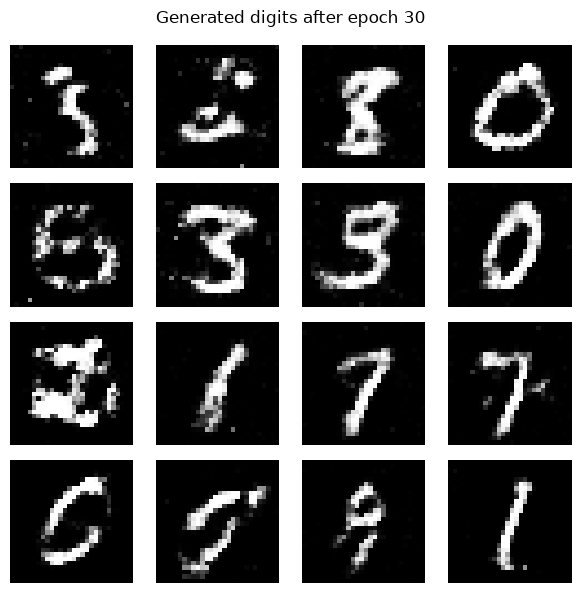

Epoch 31/50 | Generator loss: 0.8032 | Discriminator loss: 1.3186 | Time: 9.4s


2026-08-24 08:30:35.183994: I tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Epoch 32/50 | Generator loss: 0.8034 | Discriminator loss: 1.3187 | Time: 9.0s


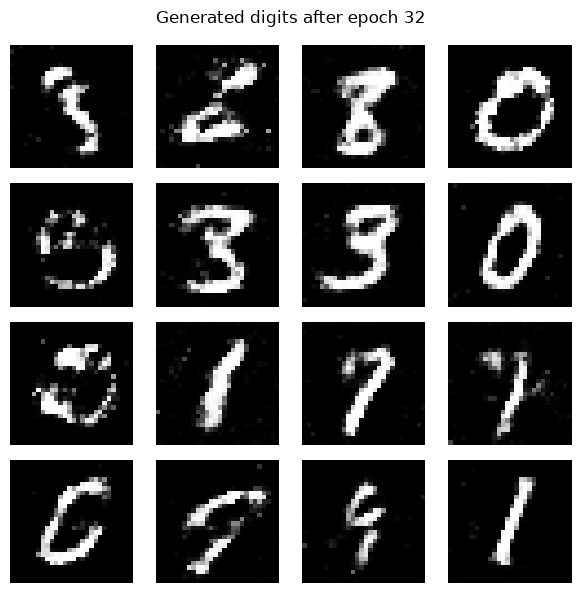

Epoch 33/50 | Generator loss: 0.7970 | Discriminator loss: 1.3237 | Time: 10.0s
Epoch 34/50 | Generator loss: 0.7986 | Discriminator loss: 1.3203 | Time: 10.7s


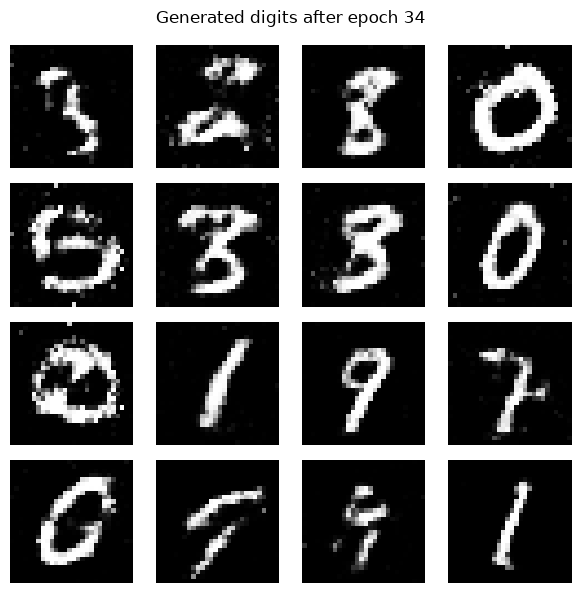

Epoch 35/50 | Generator loss: 0.7951 | Discriminator loss: 1.3258 | Time: 10.3s
Epoch 36/50 | Generator loss: 0.7921 | Discriminator loss: 1.3268 | Time: 10.2s


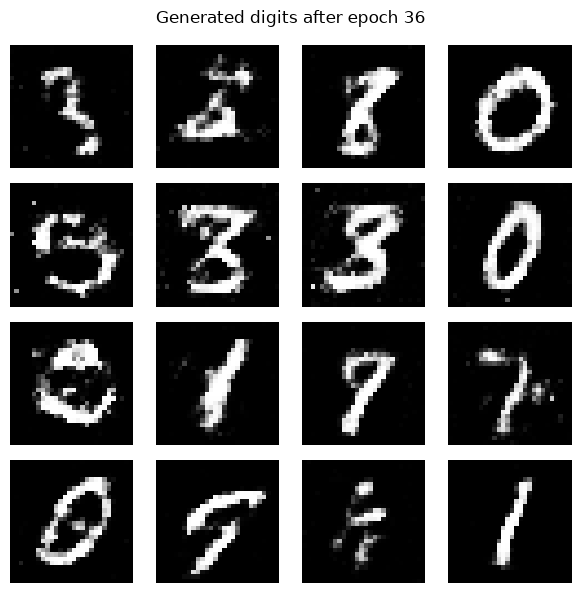

Epoch 37/50 | Generator loss: 0.7915 | Discriminator loss: 1.3286 | Time: 9.4s
Epoch 38/50 | Generator loss: 0.7904 | Discriminator loss: 1.3258 | Time: 9.5s


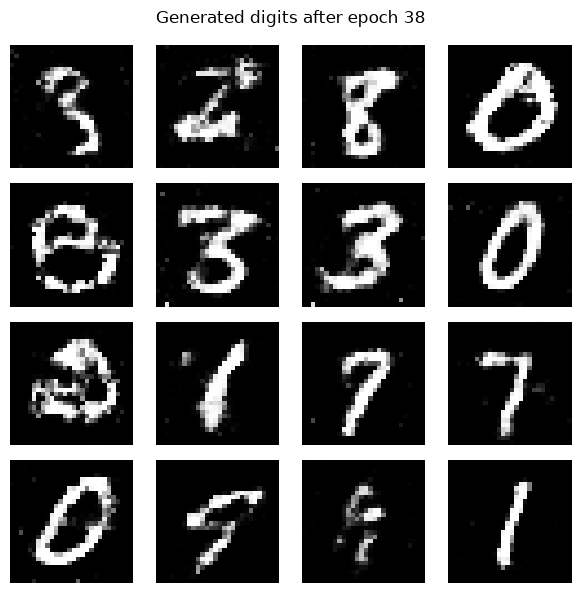

Epoch 39/50 | Generator loss: 0.7925 | Discriminator loss: 1.3261 | Time: 10.4s
Epoch 40/50 | Generator loss: 0.7884 | Discriminator loss: 1.3285 | Time: 8.9s


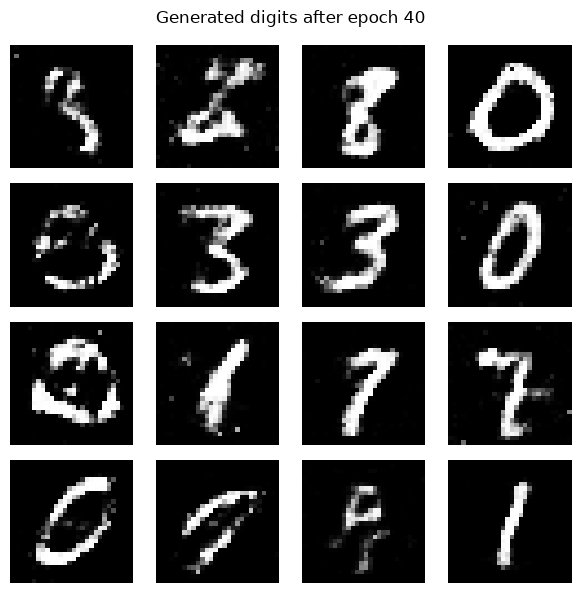

Epoch 41/50 | Generator loss: 0.7862 | Discriminator loss: 1.3297 | Time: 9.1s
Epoch 42/50 | Generator loss: 0.7868 | Discriminator loss: 1.3282 | Time: 9.4s


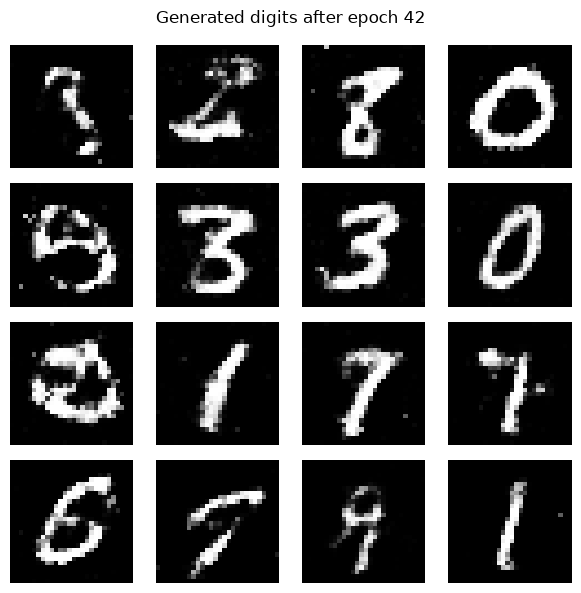

Epoch 43/50 | Generator loss: 0.7880 | Discriminator loss: 1.3287 | Time: 9.9s
Epoch 44/50 | Generator loss: 0.7876 | Discriminator loss: 1.3277 | Time: 9.0s


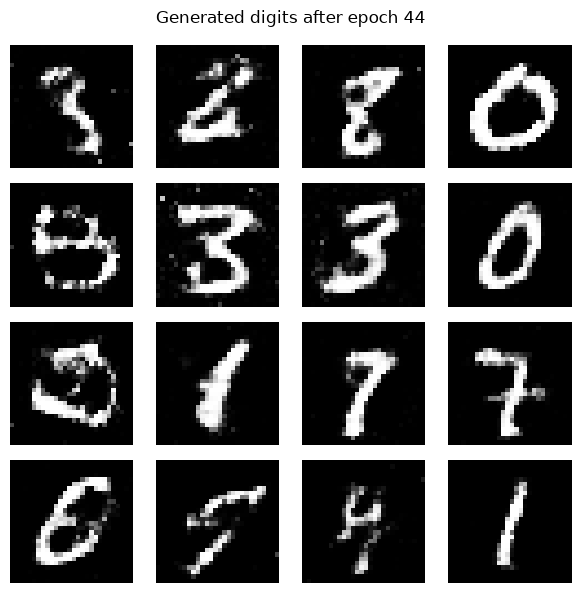

Epoch 45/50 | Generator loss: 0.7855 | Discriminator loss: 1.3315 | Time: 9.5s
Epoch 46/50 | Generator loss: 0.7885 | Discriminator loss: 1.3270 | Time: 9.3s


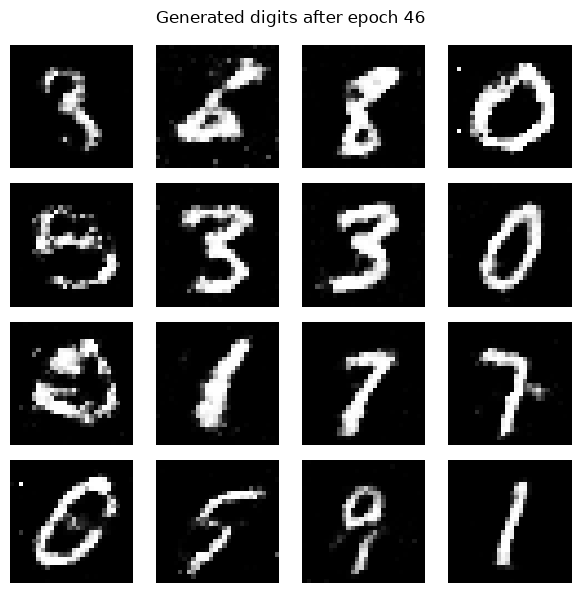

Epoch 47/50 | Generator loss: 0.7840 | Discriminator loss: 1.3324 | Time: 9.8s
Epoch 48/50 | Generator loss: 0.7830 | Discriminator loss: 1.3324 | Time: 9.2s


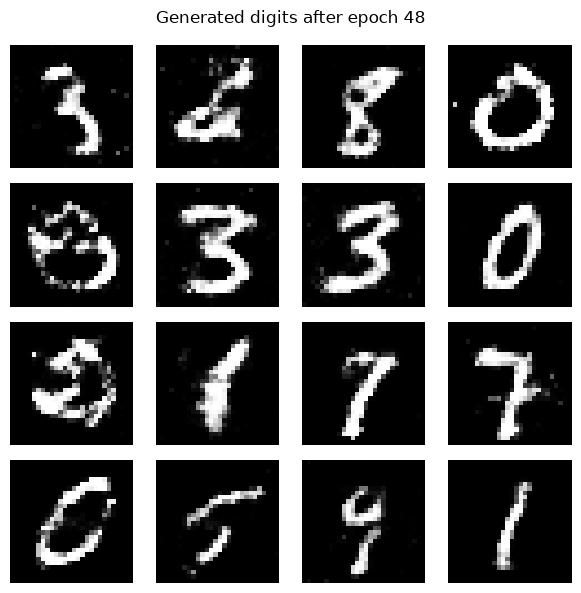

Epoch 49/50 | Generator loss: 0.7840 | Discriminator loss: 1.3303 | Time: 9.7s
Epoch 50/50 | Generator loss: 0.7858 | Discriminator loss: 1.3290 | Time: 8.9s


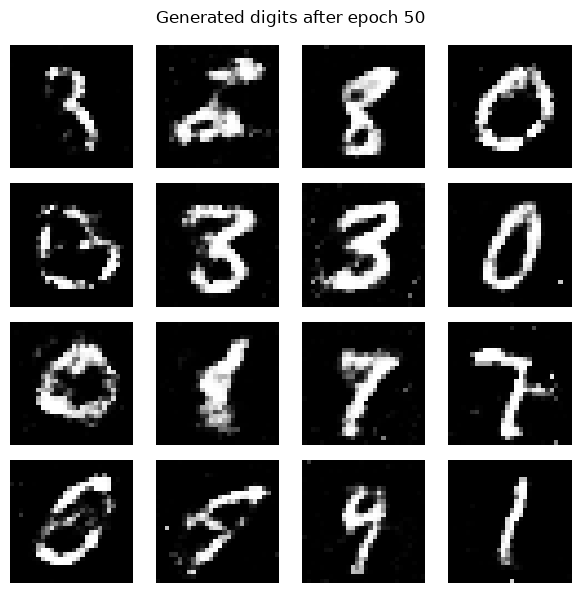

In [13]:
EPOCHS = 50
DISPLAY_EVERY = 2

gen_loss_history = []
disc_loss_history = []

def train_gan(dataset, epochs):
    for epoch in range(1, epochs + 1):
        start_time = time.time()

        batch_gen_losses = []
        batch_disc_losses = []

        for real_batch in dataset:
            gen_loss, disc_loss = train_step(real_batch)
            batch_gen_losses.append(float(gen_loss))
            batch_disc_losses.append(float(disc_loss))

        mean_gen_loss = np.mean(batch_gen_losses)
        mean_disc_loss = np.mean(batch_disc_losses)

        gen_loss_history.append(mean_gen_loss)
        disc_loss_history.append(mean_disc_loss)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Generator loss: {mean_gen_loss:.4f} | "
            f"Discriminator loss: {mean_disc_loss:.4f} | "
            f"Time: {time.time() - start_time:.1f}s"
        )

        if (
            epoch == 1
            or epoch % DISPLAY_EVERY == 0
            or epoch == epochs
        ):
            show_generated_images(
                generator, epoch=epoch
            )

train_gan(train_dataset, EPOCHS)

## 14. Plot GAN losses

GAN losses often oscillate because the Generator and Discriminator are competing.  
Visual quality of generated samples is also important.

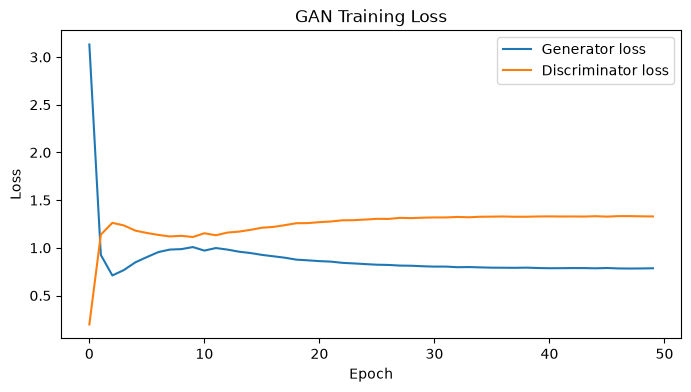

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(
    gen_loss_history,
    label="Generator loss"
)
plt.plot(
    disc_loss_history,
    label="Discriminator loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.show()

## 15. Generate new handwritten digits

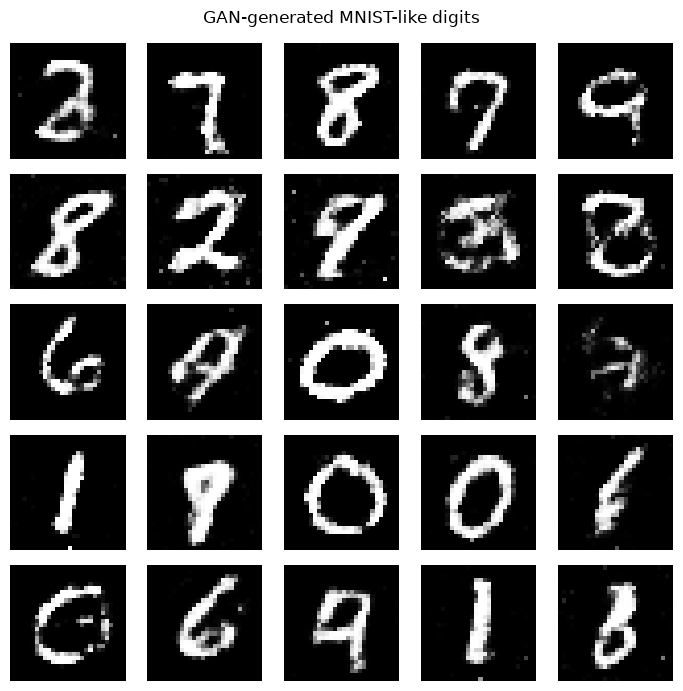

In [15]:
new_noise = tf.random.normal([25, NOISE_DIM])
new_digits = generator(
    new_noise, training=False
)
new_digits = tf.reshape(
    new_digits, (-1, 28, 28)
)

plt.figure(figsize=(7, 7))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    image = (new_digits[i] + 1.0) / 2.0
    plt.imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    plt.axis("off")

plt.suptitle(
    "GAN-generated MNIST-like digits"
)
plt.tight_layout()
plt.show()

# How to explain this experiment

### Generator
The Generator is like a **student artist**. It starts with random noise and tries to draw digits.

### Discriminator
The Discriminator is like a **teacher/detective**. It sees real MNIST images and generated images and tries to tell them apart.

### Adversarial learning
The Generator improves because it tries to fool the Discriminator.  
The Discriminator improves because it tries not to be fooled.

This competition is why the model is called a **Generative Adversarial Network**.

# Part B — Optional Digit Recognition

A normal GAN generates images but does not directly say whether an image is **0, 1, 2, ..., 9**.

For actual handwritten-digit recognition, we need a classifier.

This CPU-safe version uses a simple Dense neural network instead of convolution layers.

## 16. Prepare MNIST for recognition

In [16]:
x_train_cls = (
    x_train_original.astype("float32") / 255.0
).reshape(-1, 784)

x_test_cls = (
    x_test_original.astype("float32") / 255.0
).reshape(-1, 784)

print("Classifier train shape:", x_train_cls.shape)
print("Classifier test shape:", x_test_cls.shape)

Classifier train shape: (60000, 784)
Classifier test shape: (10000, 784)


## 17. Build a digit recognizer

In [17]:
classifier = tf.keras.Sequential(
    [
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(
            256, activation="relu"
        ),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(
            128, activation="relu"
        ),
        tf.keras.layers.Dense(
            10, activation="softmax"
        ),
    ],
    name="mnist_classifier",
)

classifier.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

classifier.summary()

Model: "mnist_classifier"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_7 (Dense)             (None, 256)               200960    
                                                                 
 dropout_2 (Dropout)         (None, 256)               0         
                                                                 
 dense_8 (Dense)             (None, 128)               32896     
                                                                 
 dense_9 (Dense)             (None, 10)                1290      
                                                                 
Total params: 235146 (918.54 KB)
Trainable params: 235146 (918.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


## 18. Train and evaluate the recognizer

In [18]:
CLASSIFIER_EPOCHS = 3

classifier.fit(
    x_train_cls,
    y_train,
    epochs=CLASSIFIER_EPOCHS,
    batch_size=128,
    validation_split=0.1,
)

test_loss, test_accuracy = classifier.evaluate(
    x_test_cls,
    y_test,
    verbose=0,
)

print(
    f"Test accuracy: "
    f"{test_accuracy * 100:.2f}%"
)

Epoch 1/3
422/422 [==============================] - 3s 6ms/step - loss: 0.3296 - accuracy: 0.9037 - val_loss: 0.1167 - val_accuracy: 0.9655
Epoch 2/3
422/422 [==============================] - 2s 5ms/step - loss: 0.1347 - accuracy: 0.9597 - val_loss: 0.0861 - val_accuracy: 0.9742
Epoch 3/3
422/422 [==============================] - 2s 5ms/step - loss: 0.0919 - accuracy: 0.9714 - val_loss: 0.0741 - val_accuracy: 0.9773
Test accuracy: 97.50%


## 19. Recognize GAN-generated digits

The classifier predicts which 0–9 class each generated image most resembles.

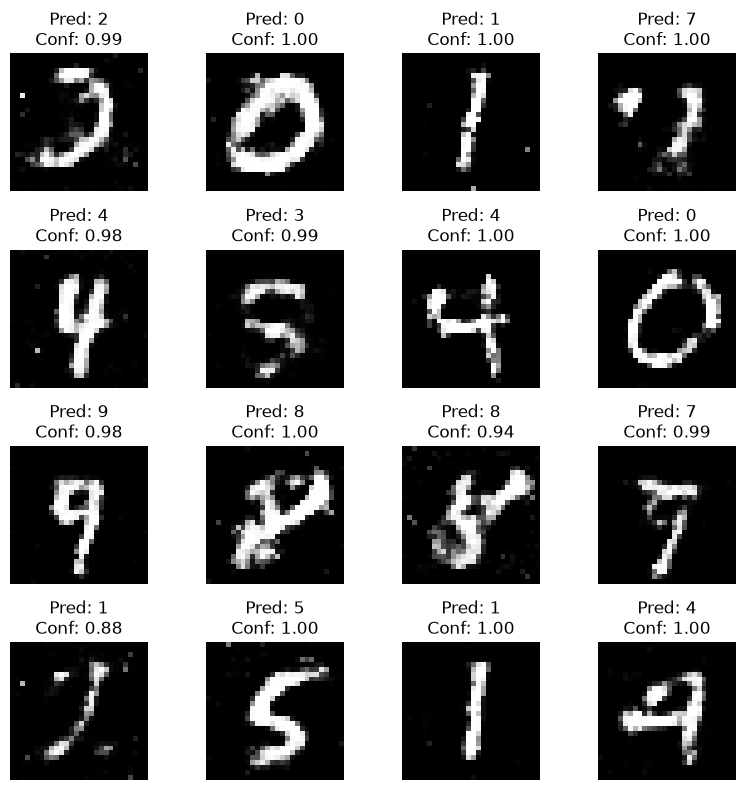

In [19]:
recognition_noise = tf.random.normal(
    [16, NOISE_DIM]
)

fake_vectors = generator(
    recognition_noise,
    training=False,
)

# Convert Generator output [-1,1] -> [0,1].
fake_for_classifier = (
    fake_vectors + 1.0
) / 2.0

fake_for_classifier = tf.clip_by_value(
    fake_for_classifier,
    0.0,
    1.0,
)

probabilities = classifier.predict(
    fake_for_classifier,
    verbose=0,
)

predicted_digits = np.argmax(
    probabilities,
    axis=1,
)

confidences = np.max(
    probabilities,
    axis=1,
)

display_images = tf.reshape(
    fake_for_classifier,
    (-1, 28, 28),
)

plt.figure(figsize=(8, 8))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        display_images[i],
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    plt.title(
        f"Pred: {predicted_digits[i]}\n"
        f"Conf: {confidences[i]:.2f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# Viva / oral questions

1. What is a GAN?
2. What are the two networks in a GAN?
3. What is random noise used for?
4. What does the Generator learn?
5. What does the Discriminator learn?
6. Why do we normalize pixels to [-1, 1]?
7. Why is `tanh` used at the Generator output?
8. Why does the Generator try to make the Discriminator output 1?
9. Why are two optimizers used?
10. What is mode collapse?
11. Why can GAN losses oscillate?
12. Does a standard GAN directly recognize 0–9 labels?
13. What is the purpose of the classifier?
14. What is a Conditional GAN?
15. How is a Dense GAN different from a DCGAN?

# Expected observation

At the beginning, generated images look random.  
After several epochs, digit-like strokes begin to appear.  
With more training, many generated samples become recognizable.

# Conclusion

This experiment implements a complete **vanilla GAN** for MNIST using Dense neural-network layers. The Generator learns to create handwritten-digit-like images while the Discriminator learns to distinguish real images from fake images.

The optional classifier demonstrates the separate task of **handwritten digit recognition**.

# Student exercises

- Change `EPOCHS` from 10 to 20.
- Change `NOISE_DIM` from 100 to 50.
- Change the Generator layer sizes.
- Change the Discriminator layer sizes.
- Change the learning rate.
- Remove Batch Normalization and compare results.
- Explain mode collapse.
- Extend the experiment into a **Conditional GAN (cGAN)** to generate a chosen digit.